# Comparação Direta: Ventilador Normal vs. Anomalia (Fita na Hélice)

## 1. Preparação, Rotulagem e Unificação dos Datasets
Para comparar diretamente o comportamento saudável com o desbalanceamento por fita na hélice (e preparar a base para Machine Learning), aplicamos o recorte das janelas estáveis de cada velocidade e criamos três colunas de metadados/rótulos:
- `velocidade`: `1` (Baixa), `2` (Média) ou `3` (Alta).
- `anomalia`: `0` para **Normal** e `1` para **Anomalia (Fita na Hélice)**.
- `estado_nome`: Rótulo textual (`Normal` vs `Fita na Hélice`) para facilitar as legendas dos gráficos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# 1. Carregando os dois arquivos CSV brutos (Ajuste os nomes dos arquivos conforme sua pasta)
caminho_normal = "C:\\Users\\santo\\OneDrive\\Área de Trabalho\\TCC\\DADOS\\DADOS_NORMAIS_1KHZ\\dados_valores_xyz_puro.csv"
caminho_fita   = "C:\\Users\\santo\\OneDrive\\Área de Trabalho\\TCC\\DADOS\\DADOS_FITA_1KHZ\\dados_valores_xyz_puro_fita.csv"

df_raw_normal = pd.read_csv(caminho_normal)
df_raw_fita   = pd.read_csv(caminho_fita)

In [3]:
# 2. Função modular para recortar as 3 velocidades e criar os rótulos (labels)
def rotular_e_recortar_dataset(df_bruto, cortes_vel, flag_anomalia, nome_estado, taxa_amostragem=1000):
    """
    Numera os segundos, filtra apenas os intervalos estáveis das 3 velocidades
    e adiciona as colunas 'velocidade', 'anomalia' (0 ou 1) e 'estado_nome'.
    """
    df = df_bruto.copy()
    df['segundo'] = np.arange(len(df)) // taxa_amostragem
    
    blocos_velocidade = []
    
    for vel_num, (inicio_s, fim_s) in cortes_vel.items():
        recorte = df[(df['segundo'] >= inicio_s) & (df['segundo'] < fim_s)].copy()
        
        # Reinicia o contador de segundos dentro de cada velocidade (0, 1, 2... até o fim do recorte)
        # Isso facilita comparar o segundo 0..500 do Normal direto com o segundo 0..500 da Anomalia!
        recorte['segundo_relativo'] = np.arange(len(recorte)) // taxa_amostragem
        
        recorte['velocidade']  = vel_num
        recorte['anomalia']    = flag_anomalia
        recorte['estado_nome'] = nome_estado
        
        blocos_velocidade.append(recorte)
        
    return pd.concat(blocos_velocidade, ignore_index=True)

In [4]:
# 3. Definindo os dicionários de corte que descobrimos nas EDAs individuais
cortes_normal = {
    1: (20, 620),    # 600 segundos estáveis
    2: (660, 1230),  # 570 segundos estáveis
    3: (1270, 1780)  # 510 segundos estáveis
}

cortes_fita = {
    1: (20, 580),    # 560 segundos estáveis
    2: (620, 1170),  # 550 segundos estáveis
    3: (1210, 1800)  # 590 segundos estáveis
}

In [5]:
# 4. Processando e unificando os dois datasets em um único DataFrame Mestre!
df_normal_proc = rotular_e_recortar_dataset(df_raw_normal, cortes_normal, flag_anomalia=0, nome_estado="Normal")
df_fita_proc   = rotular_e_recortar_dataset(df_raw_fita,   cortes_fita,   flag_anomalia=1, nome_estado="Fita na Hélice")

df_unificado = pd.concat([df_normal_proc, df_fita_proc], ignore_index=True)

# 5. Exibindo um resumo da nova base unificada para validação
resumo_base = df_unificado.groupby(['anomalia', 'estado_nome', 'velocidade']).agg(
    Total_Linhas=('x', 'count'),
    Total_Segundos=('segundo_relativo', 'nunique'),
    Std_X=('x', 'std'),
    Std_Y=('y', 'std'),
    Std_Z=('z', 'std')
).reset_index()

print(f"Dataset Unificado criado com sucesso! Total de linhas: {len(df_unificado):,}")
display(resumo_base.round(4))

Dataset Unificado criado com sucesso! Total de linhas: 3,380,000


,anomalia,estado_nome,velocidade,Total_Linhas,Total_Segundos,Std_X,Std_Y,Std_Z
0,0,Normal,1,600000,600,0.7766,0.7963,0.2268
1,0,Normal,2,570000,570,2.4262,1.3883,0.6424
2,0,Normal,3,510000,510,1.2704,0.7961,0.4528
3,1,Fita na Hélice,1,560000,560,1.3177,0.9566,0.2867
4,1,Fita na Hélice,2,550000,550,7.9620,7.1268,3.9566
5,1,Fita na Hélice,3,590000,590,4.0013,6.4955,5.4322


## 2. Comparação no Domínio do Tempo: Evolução do Desvio Padrão (`STD`)
Agrupando o dataset unificado a cada 1 segundo, sobrepomos a intensidade de vibração do ventilador **Normal (`anomalia = 0`)** contra o ventilador com **Fita na Hélice (`anomalia = 1`)** nas 3 velocidades.

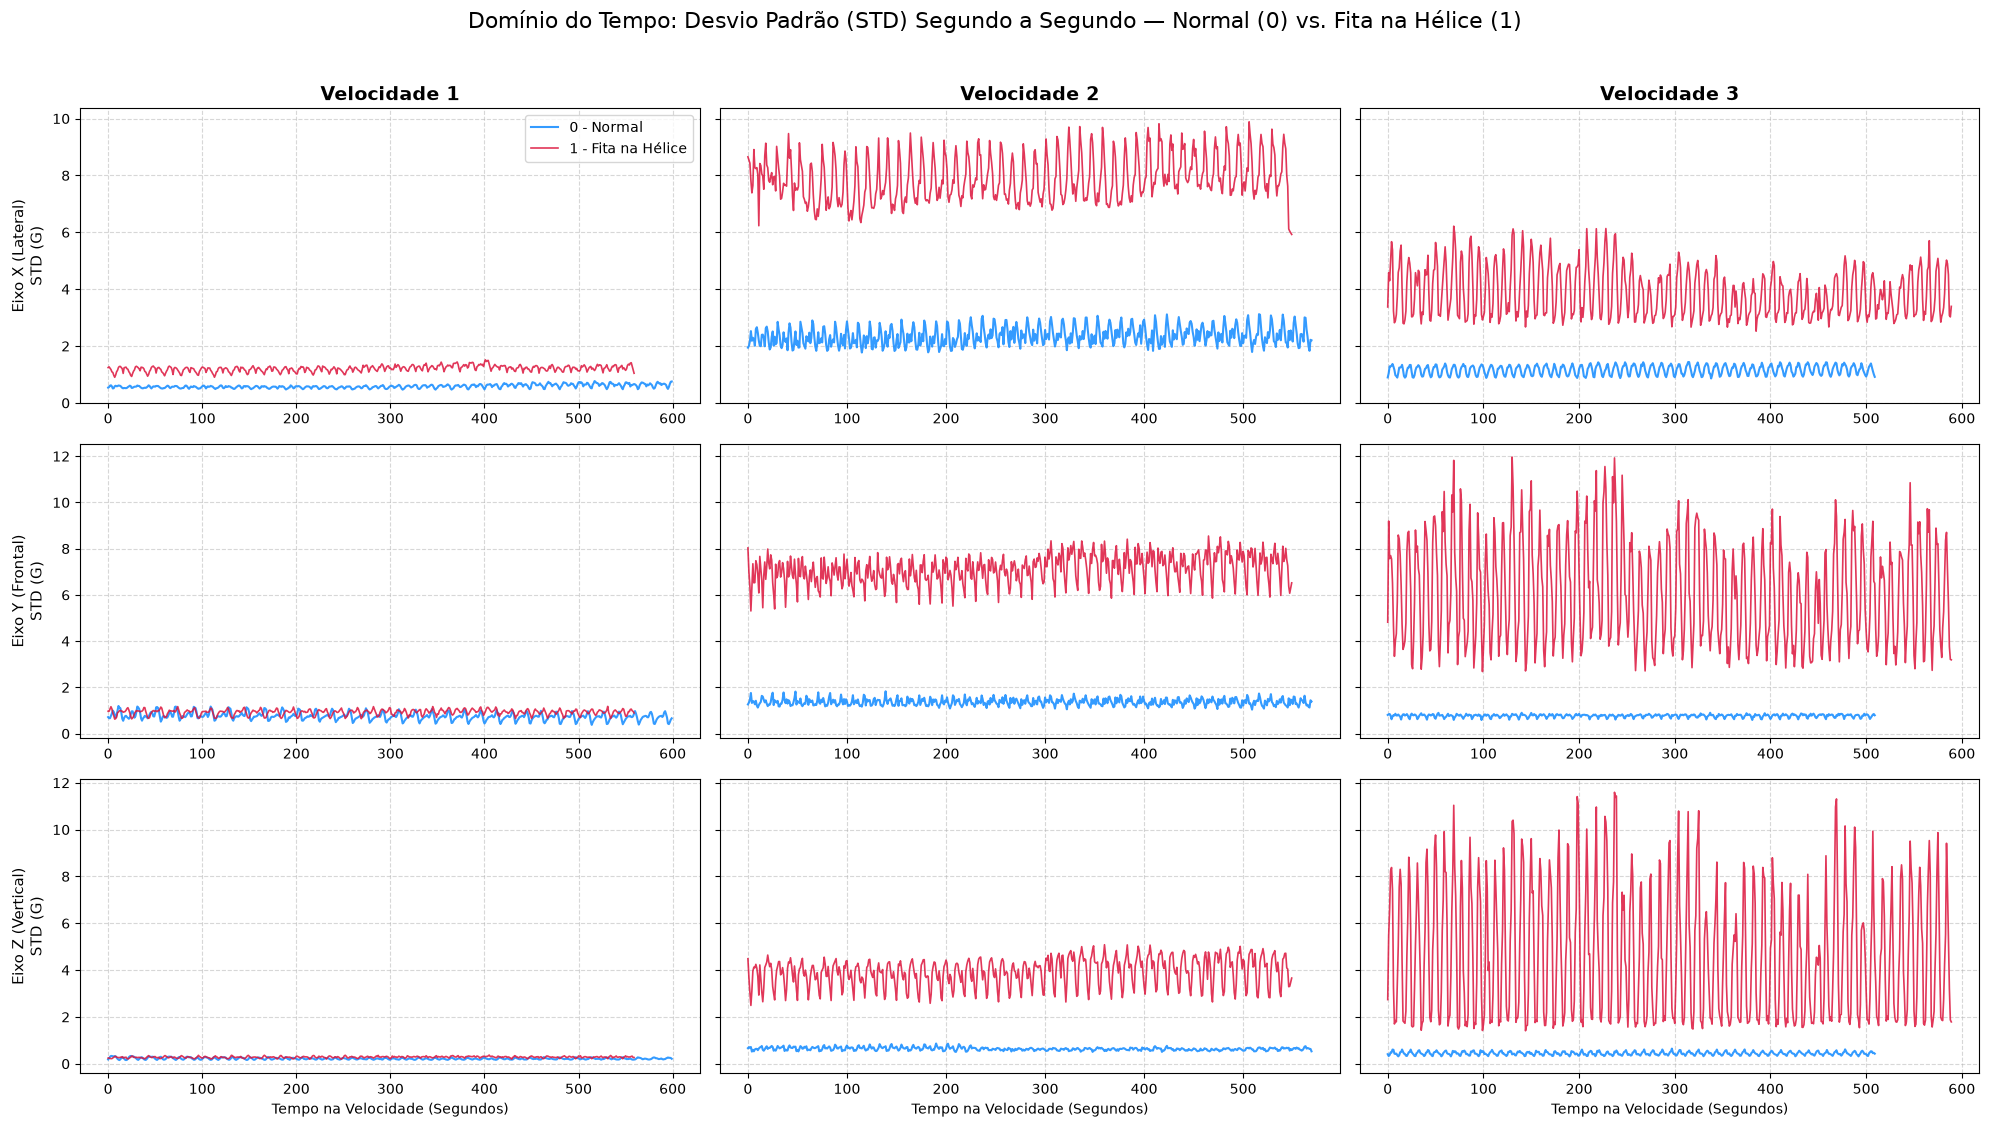

In [6]:
# Calculando o Desvio Padrão para cada segundo de cada condição e velocidade
df_std_comparativo = df_unificado.groupby(
    ['anomalia', 'estado_nome', 'velocidade', 'segundo_relativo']
)[['x', 'y', 'z']].std().reset_index()

# Plotando painel 3x3 (Linhas = Eixos X, Y, Z | Colunas = Velocidades 1, 2, 3)
fig, axs = plt.subplots(3, 3, figsize=(20, 11), sharey='row')
fig.suptitle("Domínio do Tempo: Desvio Padrão (STD) Segundo a Segundo — Normal (0) vs. Fita na Hélice (1)", fontsize=16, y=1.02)

eixos_col = ['x', 'y', 'z']
nomes_eixos = ['Eixo X (Lateral)', 'Eixo Y (Frontal)', 'Eixo Z (Vertical)']

for linha_eixo in range(3):
    eixo = eixos_col[linha_eixo]
    for col_vel in range(3):
        vel = col_vel + 1
        ax = axs[linha_eixo, col_vel]
        
        # Filtrando Normal (0) e Anomalia (1) para a velocidade atual
        dados_norm = df_std_comparativo[(df_std_comparativo['anomalia'] == 0) & (df_std_comparativo['velocidade'] == vel)]
        dados_anom = df_std_comparativo[(df_std_comparativo['anomalia'] == 1) & (df_std_comparativo['velocidade'] == vel)]
        
        # Plotando as duas curvas juntas
        ax.plot(dados_norm['segundo_relativo'], dados_norm[eixo], color='dodgerblue', linewidth=1.5, label='0 - Normal', alpha=0.9)
        ax.plot(dados_anom['segundo_relativo'], dados_anom[eixo], color='crimson', linewidth=1.2, label='1 - Fita na Hélice', alpha=0.85)
        
        if linha_eixo == 0:
            ax.set_title(f"Velocidade {vel}", fontsize=14, fontweight='bold')
        if col_vel == 0:
            ax.set_ylabel(f"{nomes_eixos[linha_eixo]}\nSTD (G)", fontsize=11)
        if linha_eixo == 2:
            ax.set_xlabel("Tempo na Velocidade (Segundos)")
            
        ax.grid(True, linestyle='--', alpha=0.5)
        if linha_eixo == 0 and col_vel == 0:
            ax.legend(loc='upper right', fontsize=10)

plt.tight_layout()
plt.show()

## 3. Comparação Espacial 3D dos Clusters de Desvio Padrão (`STD`)
Plotamos os pontos estatísticos de 1 segundo do estado **Normal (`0`)** e da **Anomalia (`1`)** no mesmo espaço tridimensional `(X, Y, Z)`. Essa visualização valida geometricamente como algoritmos baseados em distância (como K-Means) ou árvores de decisão conseguem separar o estado saudável do defeito.

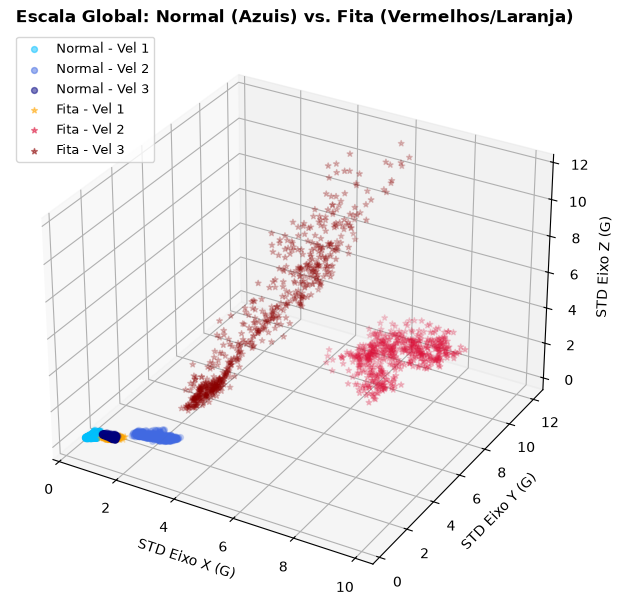

In [10]:
fig = plt.figure(figsize=(12, 10))

# --- SUBPLOT 1: Visão Geral (Todas as Velocidades Juntas: Normal vs Anomalia) ---
ax1 = fig.add_subplot(1, 2, 1, projection='3d')

estilos = [
    # (anomalia, velocidade, cor, marcador, legenda)
    (0, 1, 'deepskyblue', 'o', 'Normal - Vel 1'),
    (0, 2, 'royalblue',   'o', 'Normal - Vel 2'),
    (0, 3, 'navy',        'o', 'Normal - Vel 3'),
    (1, 1, 'orange',      '*', 'Fita - Vel 1'),
    (1, 2, 'crimson',     '*', 'Fita - Vel 2'),
    (1, 3, 'darkred',     '*', 'Fita - Vel 3'),
]

for flag_anom, vel, cor, marcador, texto_legenda in estilos:
    sub = df_std_comparativo[(df_std_comparativo['anomalia'] == flag_anom) & (df_std_comparativo['velocidade'] == vel)]
    ax1.scatter(sub['x'], sub['y'], sub['z'], c=cor, marker=marcador, alpha=0.5, s=18, label=texto_legenda)

ax1.set_title("Escala Global: Normal (Azuis) vs. Fita (Vermelhos/Laranja)", fontsize=12, fontweight='bold')
ax1.set_xlabel("STD Eixo X (G)")
ax1.set_ylabel("STD Eixo Y (G)")
ax1.set_zlabel("STD Eixo Z (G)")
ax1.legend(loc='upper left', fontsize=9)

plt.tight_layout()
plt.show()

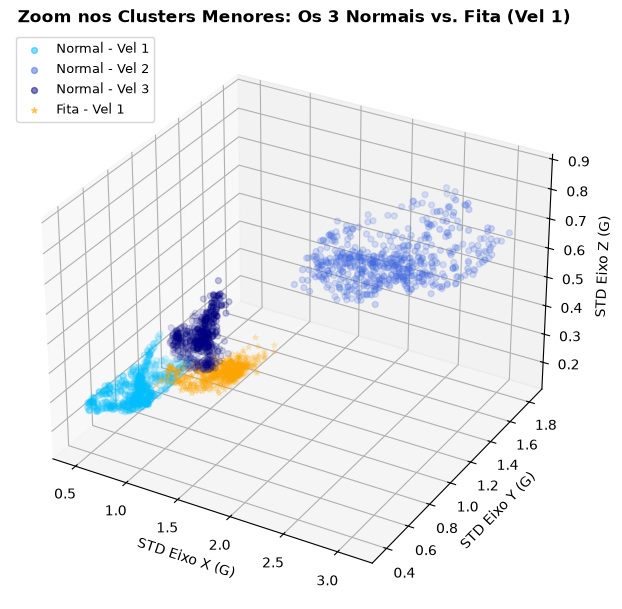

In [11]:
fig = plt.figure(figsize=(12, 10))

# --- SUBPLOT 2: Zoom na Região de Baixa Energia (Velocidade 1 Normal vs Velocidades Normais e Fita Vel 1) ---
ax2 = fig.add_subplot(1, 2, 2, projection='3d')

for flag_anom, vel, cor, marcador, texto_legenda in estilos[:4]: # Plota os 3 Normais + Fita Vel 1
    sub = df_std_comparativo[(df_std_comparativo['anomalia'] == flag_anom) & (df_std_comparativo['velocidade'] == vel)]
    ax2.scatter(sub['x'], sub['y'], sub['z'], c=cor, marker=marcador, alpha=0.5, s=18, label=texto_legenda)

ax2.set_title("Zoom nos Clusters Menores: Os 3 Normais vs. Fita (Vel 1)", fontsize=12, fontweight='bold')
ax2.set_xlabel("STD Eixo X (G)")
ax2.set_ylabel("STD Eixo Y (G)")
ax2.set_zlabel("STD Eixo Z (G)")
ax2.legend(loc='upper left', fontsize=9)

plt.tight_layout()
plt.show()

## 4. Comparação no Domínio da Frequência: FFT com Hanning (Normal vs. Fita na Hélice)
Utilizando a função de FFT Tratada (janela de 5 segundos = 5000 amostras, Janela de Hanning e filtro passa-alta `f > 5 Hz`), sobrepomos a assinatura espectral do ventilador **Normal (`0`)** e com **Fita na Hélice (`1`)** para evidenciar o crescimento das harmônicas mecânicas frente à estabilidade do pico elétrico de **120 Hz**.

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

def extrair_fft_comparativa(df_unif, flag_anomalia, vel_num, segundos=5, taxa_amostragem=1000):
    """
    Filtra o df_unificado pela condição (0=Normal ou 1=Fita) e velocidade (1, 2 ou 3),
    recorta 5 segundos (5000 pontos) e retorna a FFT com Hanning (> 5 Hz).
    """
    N = segundos * taxa_amostragem
    recorte = df_unif[(df_unif['anomalia'] == flag_anomalia) & (df_unif['velocidade'] == vel_num)].iloc[:N]
    
    janela = np.hanning(N)
    freqs = np.fft.rfftfreq(N, d=1.0 / taxa_amostragem)
    
    fft_x = np.abs(np.fft.rfft((recorte['x'] - recorte['x'].mean()) * janela)) * (4.0 / N)
    fft_y = np.abs(np.fft.rfft((recorte['y'] - recorte['y'].mean()) * janela)) * (4.0 / N)
    fft_z = np.abs(np.fft.rfft((recorte['z'] - recorte['z'].mean()) * janela)) * (4.0 / N)
    
    mascara = freqs > 5.0
    return freqs[mascara], {'x': fft_x[mascara], 'y': fft_y[mascara], 'z': fft_z[mascara]}


def plotar_comparacao_fft_por_eixo(df_unif, eixo_escolhido, nome_eixo):
    """
    Gera um painel com 3 gráficos grandes (Velocidade 1, Velocidade 2 e Velocidade 3)
    para um único eixo ('x', 'y' ou 'z'), sobrepondo Normal (0) vs. Fita na Hélice (1).
    """
    fig, axs = plt.subplots(3, 1, figsize=(16, 10), sharex=True)
    fig.suptitle(f"Comparação FFT com Hanning — {nome_eixo}: Normal (Azul) vs. Fita na Hélice (Vermelho)", 
                 fontsize=15, fontweight='bold', y=1.01)
    
    titulos_vel = [
        "Velocidade 1 (Baixa - Giro ~11.2 a 12.6 Hz)",
        "Velocidade 2 (Média / Ressonância - Giro ~19.3 a 19.5 Hz)",
        "Velocidade 3 (Alta - Giro ~23.2 a 23.5 Hz)"
    ]
    
    for i, vel in enumerate([1, 2, 3]):
        ax = axs[i]
        
        # Extraindo FFT Normal (0) e Anomalia (1) para a velocidade atual
        freqs, fft_norm = extrair_fft_comparativa(df_unif, flag_anomalia=0, vel_num=vel)
        _,     fft_anom = extrair_fft_comparativa(df_unif, flag_anomalia=1, vel_num=vel)
        
        # Plotando Fita na Hélice (Vermelho com leve preenchimento) e Normal (Azul nítido)
        ax.plot(freqs, fft_anom[eixo_escolhido], color='crimson', linewidth=1.2, alpha=0.85, label='1 - Fita na Hélice (Anomalia)')
        ax.fill_between(freqs, fft_anom[eixo_escolhido], color='crimson', alpha=0.15)
        
        ax.plot(freqs, fft_norm[eixo_escolhido], color='dodgerblue', linewidth=1.3, alpha=0.95, label='0 - Normal (Saudável)')
        ax.fill_between(freqs, fft_norm[eixo_escolhido], color='dodgerblue', alpha=0.25)
        
        # Marcando os 120 Hz e 240 Hz da rede elétrica
        ax.axvline(120, color='black', linestyle='-.', alpha=0.6, label='Ruído Elétrico (120/240 Hz)')
        ax.axvline(240, color='black', linestyle='-.', alpha=0.6)
        
        # Ajustes de títulos e régua de 10 em 10 Hz
        ax.set_title(titulos_vel[i], fontsize=12, fontweight='bold')
        ax.set_ylabel("Magnitude (G)", fontsize=11)
        ax.set_xlim(5, 300)
        ax.set_xticks(np.arange(0, 301, 10))
        ax.xaxis.set_minor_locator(MultipleLocator(5))
        
        ax.grid(which='major', linestyle='--', alpha=0.6)
        ax.grid(which='minor', linestyle=':', alpha=0.3)
        ax.legend(loc='upper right', fontsize=10)
        
    axs[2].set_xlabel("Frequência (Hz) - Escala Detalhada de 10 em 10 Hz", fontsize=12)
    plt.tight_layout()
    plt.show()

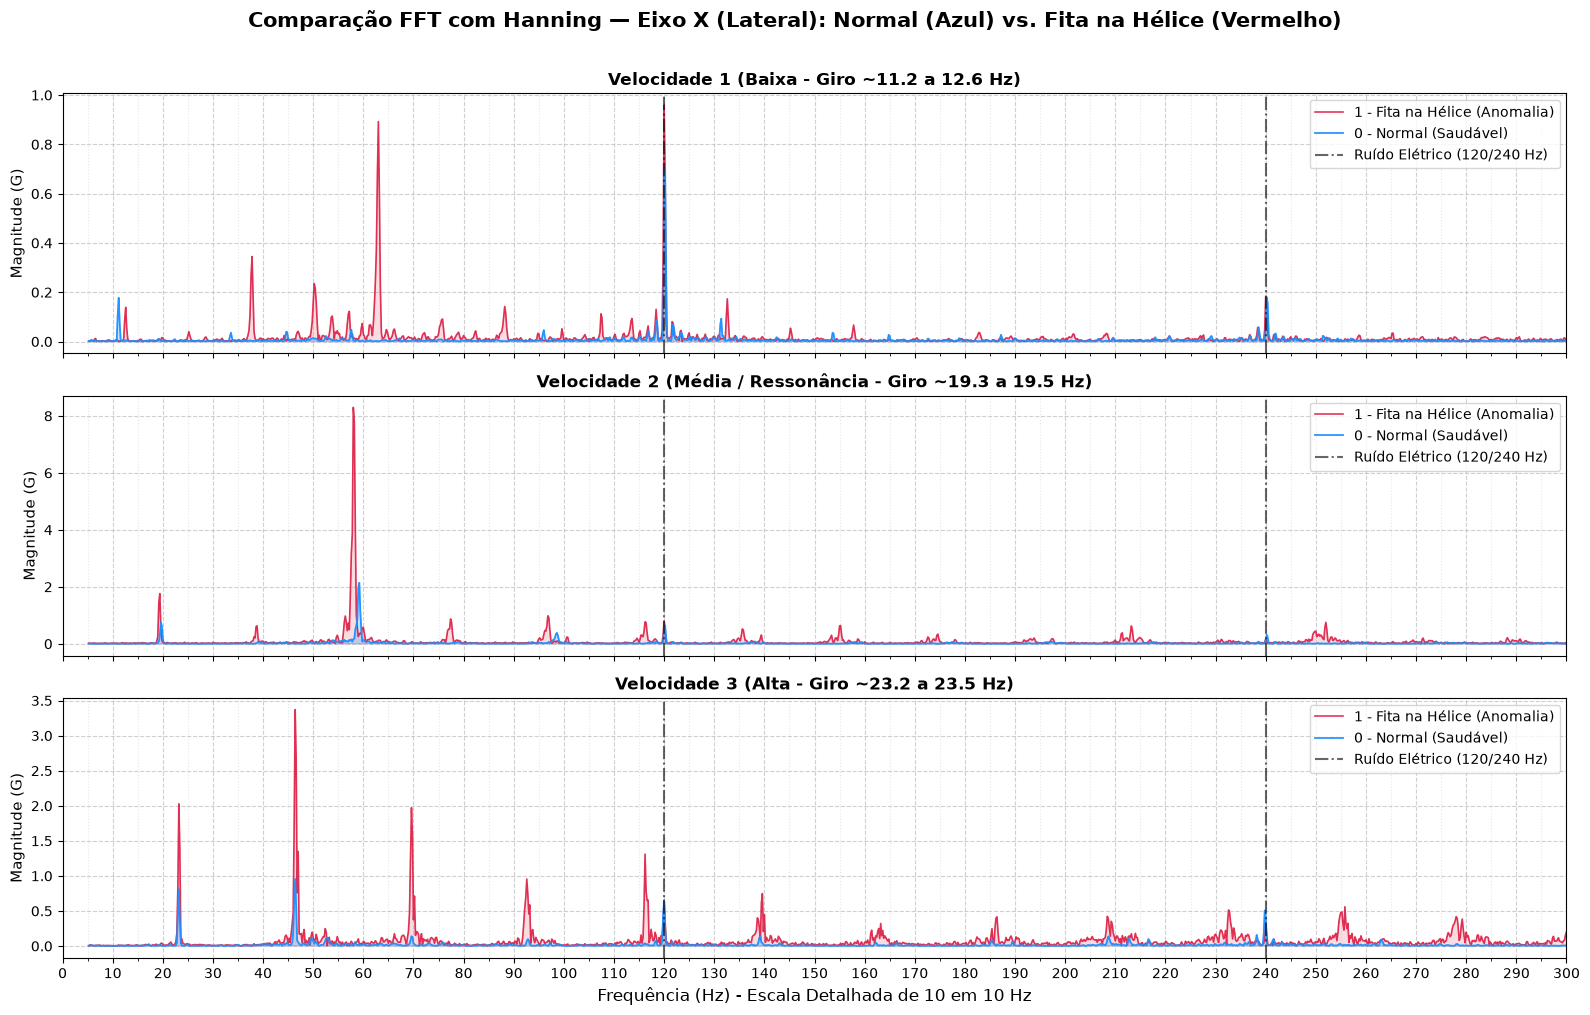

In [14]:
# 1. Comparando Velocidades 1, 2 e 3 no EIXO X (Lateral)
plotar_comparacao_fft_por_eixo(df_unificado, eixo_escolhido='x', nome_eixo='Eixo X (Lateral)')

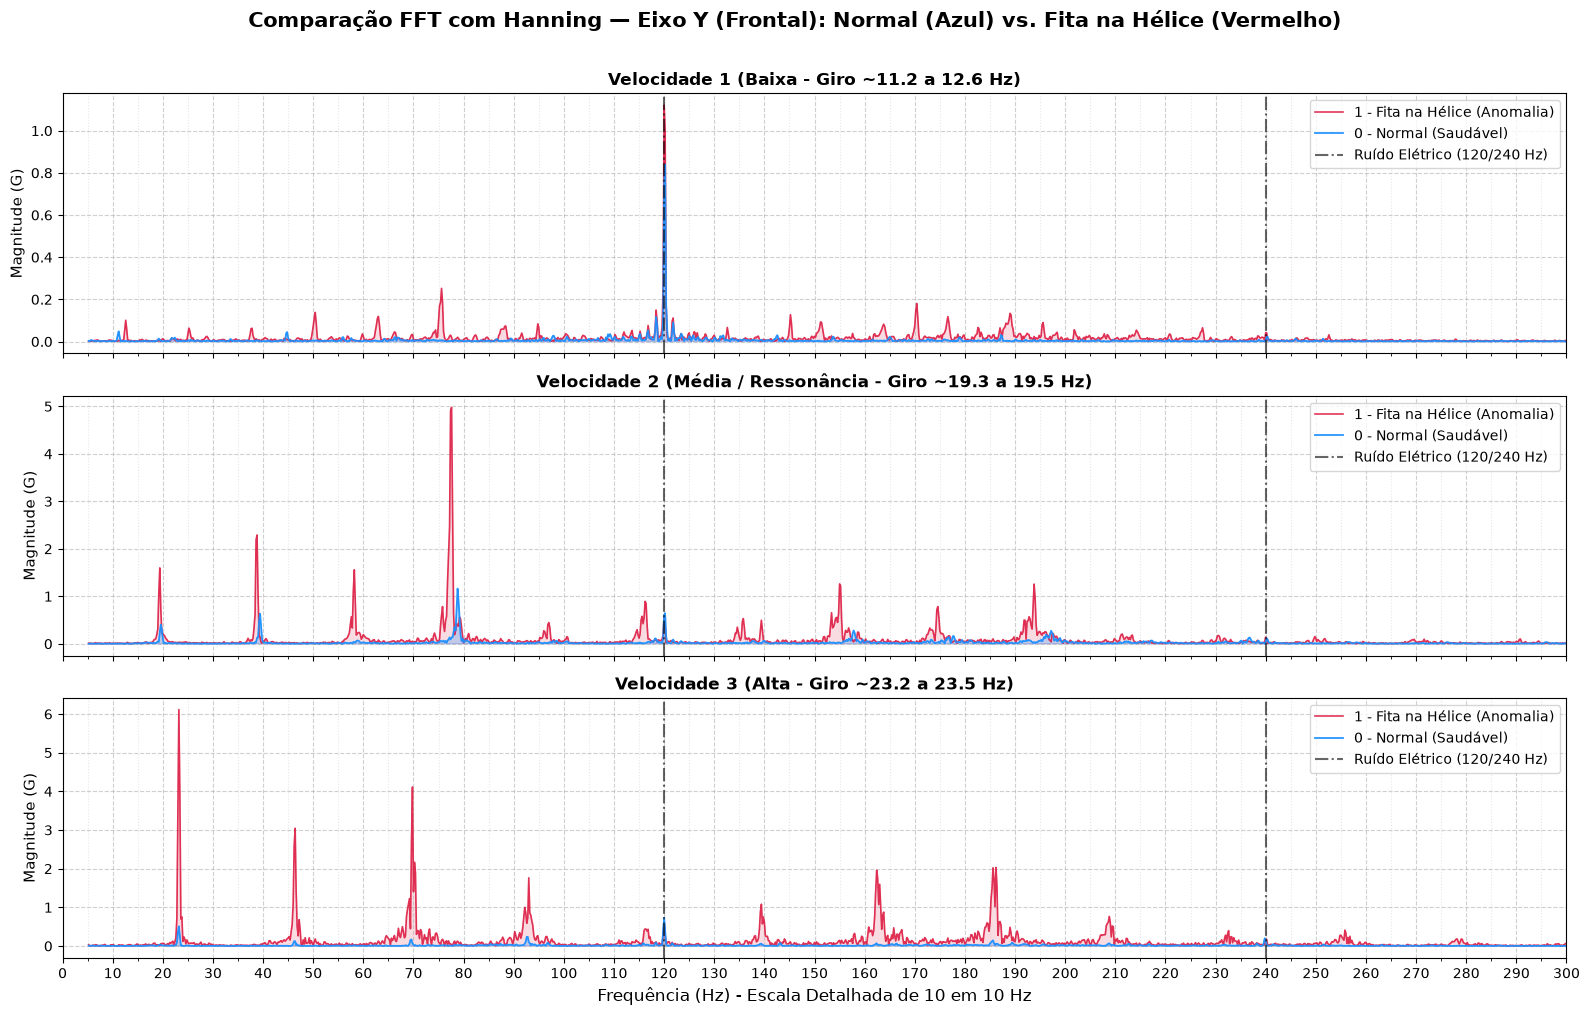

In [15]:
# 2. Comparando Velocidades 1, 2 e 3 no EIXO Y (Frontal)
plotar_comparacao_fft_por_eixo(df_unificado, eixo_escolhido='y', nome_eixo='Eixo Y (Frontal)')

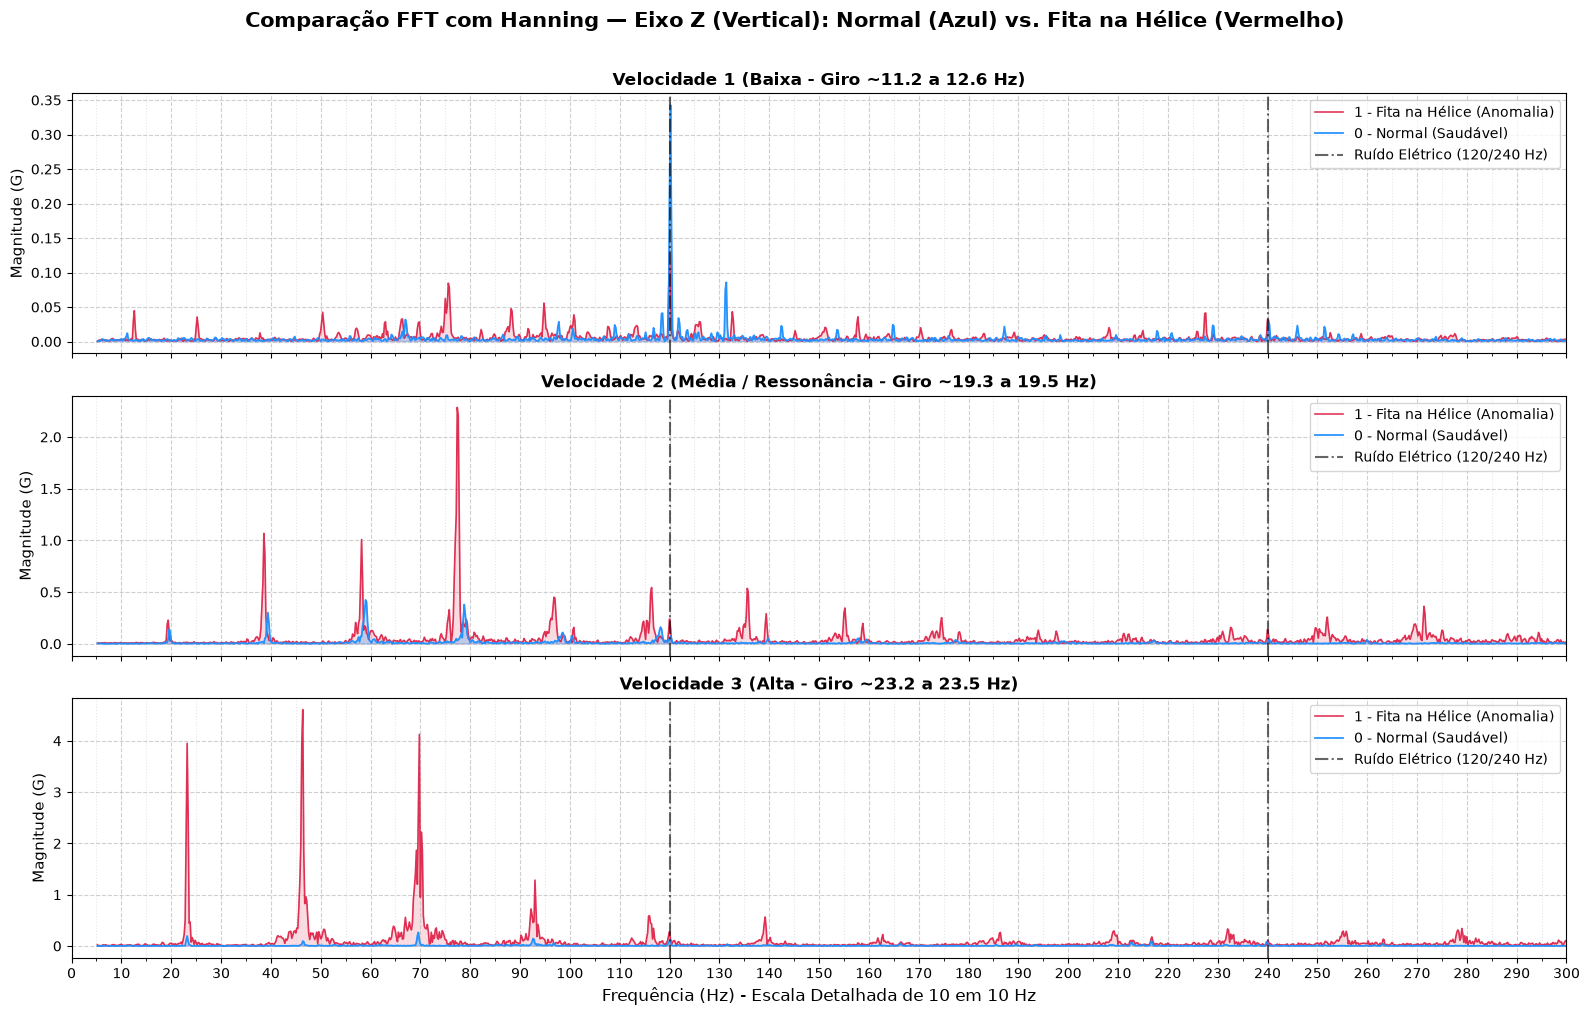

In [16]:
# 3. Comparando Velocidades 1, 2 e 3 no EIXO Z (Vertical)
plotar_comparacao_fft_por_eixo(df_unificado, eixo_escolhido='z', nome_eixo='Eixo Z (Vertical)')